In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [2]:
billboard = pd.read_csv('billboard.csv')

In [3]:
# setting up model
target = "weeks_at_number_one"
X = billboard.drop(columns=[target, "non_consecutive"])
y = billboard[target]
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns

In [4]:
# preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
            ("cat",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            cat_cols,),])

In [5]:
# combine model and preprocessor
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
            ("regressor",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=10,
                min_samples_leaf=3,
                random_state=42,
                n_jobs=-1,
            ),),])

In [6]:
# splitting data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model.fit(X_train, y_train)

# make predictions, get evaluation metrics
y_pred = model.predict(X_test)
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f} weeks")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.2f} weeks")
print(f"R2: {r2_score(y_test, y_pred):.2f}")

MAE: 1.76 weeks
RMSE: 2.52 weeks
R2: 0.10


In [7]:
# calculating feature importance
preprocessor = model.named_steps["preprocessor"]
encoded_importances = model.named_steps["regressor"].feature_importances_
importances_by_variable = dict(
    zip(num_cols, encoded_importances[preprocessor.output_indices_["num"]])
)
categorical_importances = encoded_importances[preprocessor.output_indices_["cat"]]
encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
offset = 0
for variable, categories in zip(cat_cols, encoder.categories_):
    width = len(categories)
    importances_by_variable[variable] = categorical_importances[offset : offset + width].sum()
    offset += width

importances = pd.Series(importances_by_variable).nlargest(20).sort_values()

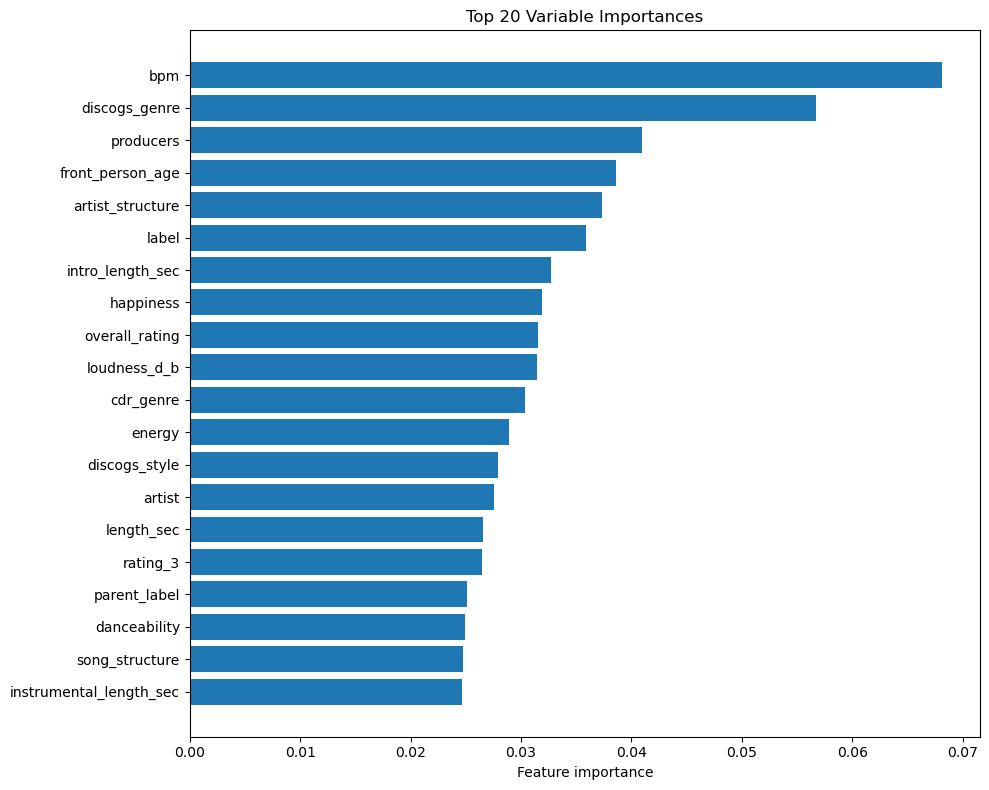

In [8]:
#plot feature importance
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(importances.index.astype(str), importances.to_numpy(dtype=float))
ax.set_xlabel("Feature importance")
ax.set_title("Top 20 Variable Importances")
fig.tight_layout()
plt.show()

In [9]:
# calculating prediction differences
weeks_test_results = pd.DataFrame(
    {
        "song": X_test["song"],
        "date": pd.to_datetime(X_test["date"], utc=True),
        "actual_weeks_at_number_one": y_test,
        "predicted_weeks_at_number_one": y_pred,
    }
).sort_values("date")
weeks_test_results["difference_weeks"] = (
    weeks_test_results["actual_weeks_at_number_one"] - weeks_test_results["predicted_weeks_at_number_one"]
)
weeks_at_number_one_difference = weeks_test_results["difference_weeks"]

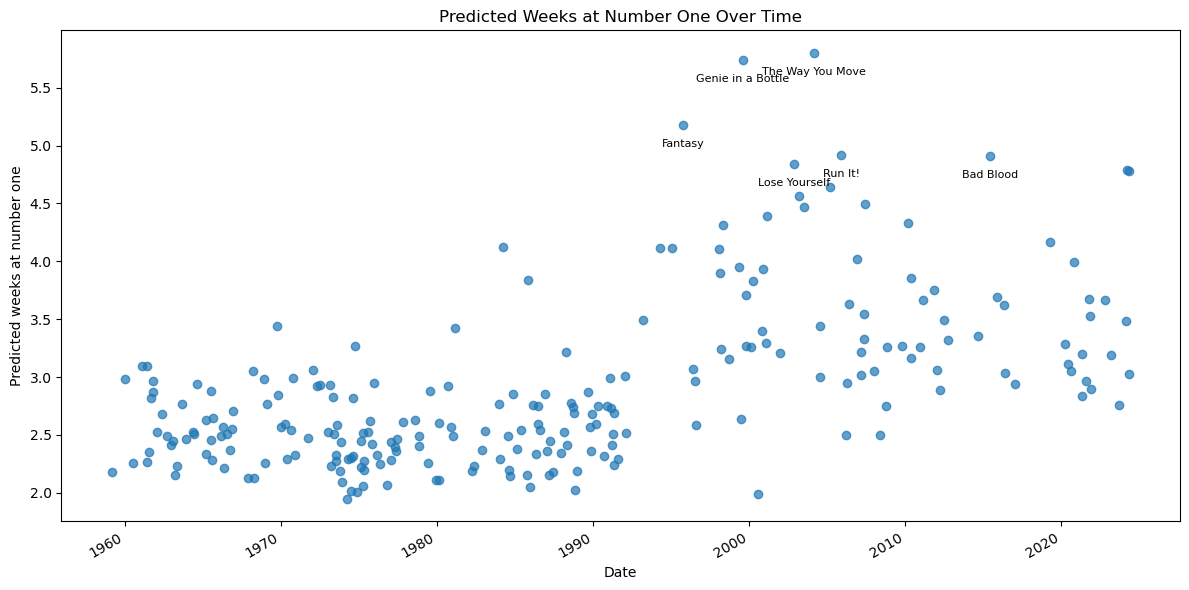

In [10]:
#plotting predicted weeks at #1
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(
    weeks_test_results["date"],
    weeks_test_results["predicted_weeks_at_number_one"],
    alpha=0.7,
)
for _, song in weeks_test_results.loc[weeks_test_results["predicted_weeks_at_number_one"] > 4.8].iterrows():
    ax.annotate(
        song["song"],
        xy=(song["date"], song["predicted_weeks_at_number_one"]),
        xytext=(0, -10),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=8,
    )
ax.set_xlabel("Date")
ax.set_ylabel("Predicted weeks at number one")
ax.set_title("Predicted Weeks at Number One Over Time")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

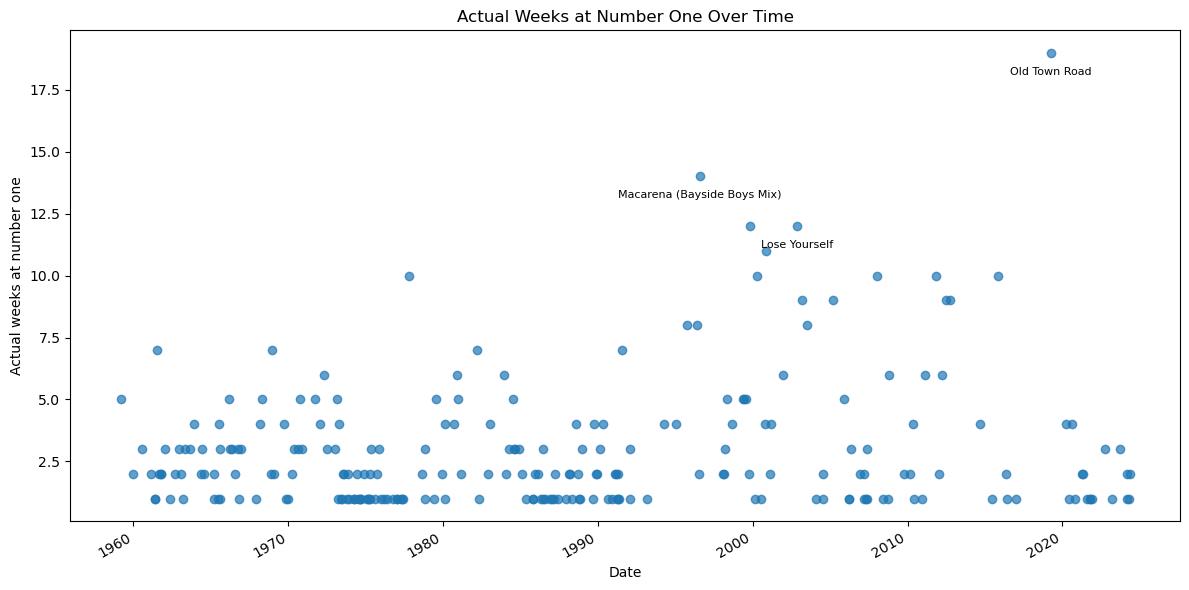

In [11]:
#plotting actual weeks at #1
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(
    weeks_test_results["date"],
    weeks_test_results["actual_weeks_at_number_one"],
    alpha=0.7,
)
for _, song in weeks_test_results.loc[weeks_test_results["actual_weeks_at_number_one"] > 11].iterrows():
    if song["song"] == "Smooth":
        continue
    ax.annotate(
        song["song"],
        xy=(song["date"], song["actual_weeks_at_number_one"]),
        xytext=(0, -10),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=8,
    )

ax.set_xlabel("Date")
ax.set_ylabel("Actual weeks at number one")
ax.set_title("Actual Weeks at Number One Over Time")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

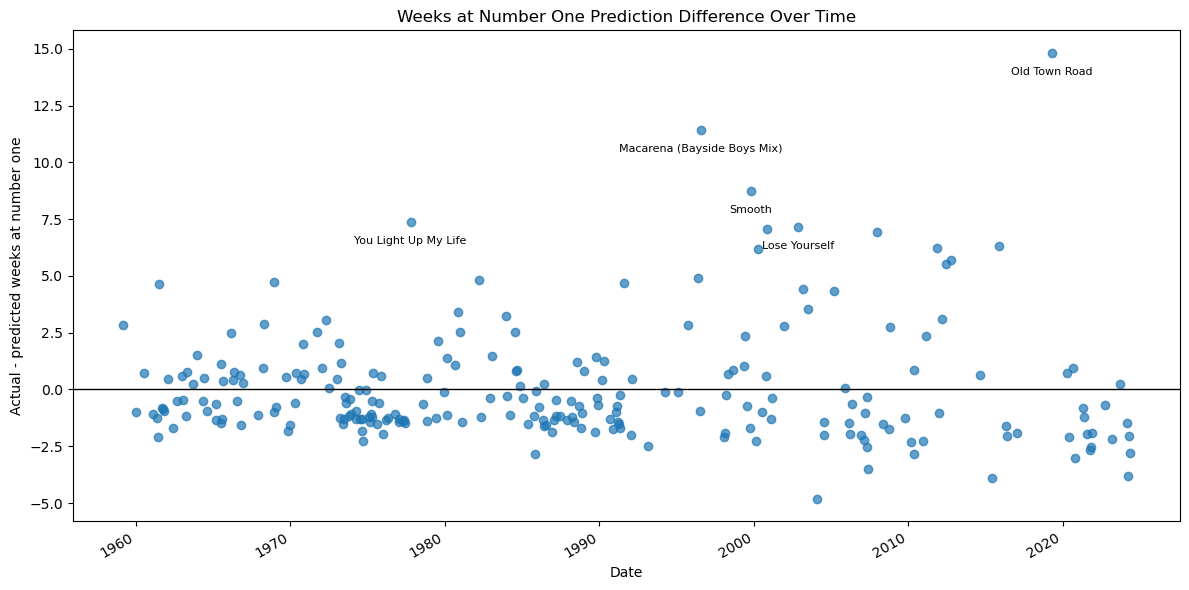

In [12]:
#plotting prediction differences
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(weeks_test_results["date"], weeks_at_number_one_difference, alpha=0.7)
for _, song in weeks_test_results.loc[weeks_test_results["difference_weeks"] > 7].iterrows():
    if song["song"] == "Independent Women, Part 1":
        continue
    ax.annotate(
        song["song"],
        xy=(song["date"], song["difference_weeks"]),
        xytext=(0, -10),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=8,
    )
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Date")
ax.set_ylabel("Actual - predicted weeks at number one")
ax.set_title("Weeks at Number One Prediction Difference Over Time")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

Findings:

The model tends to predict safely, with most of it's predictions being between 1 and 5 weeks, which makes sense because that's how long most #1 hits stay at that spot. It also has a hard time predicting when songs stay at #1 for a long time. I was very interested to see that starting in the 1995/2000 range, it got more lenient with the predictions. I imagine this might be because before that, songs tended to have much shorter durations at #1. 

In [13]:
# further exploration
weeks_test_results = weeks_test_results.sort_values("difference_weeks")
print(weeks_test_results.head(3))
print(weeks_test_results.tail(3))
weeks_test_results["abs_value"] = weeks_test_results["difference_weeks"].abs()
weeks_test_results = weeks_test_results.sort_values("abs_value", ascending=False)
print(weeks_test_results.tail(3))


                  song                      date  actual_weeks_at_number_one  \
899   The Way You Move 2004-02-14 00:00:00+00:00                           1   
1042         Bad Blood 2015-06-06 00:00:00+00:00                           1   
1164          CARNIVAL 2024-03-16 00:00:00+00:00                           1   

      predicted_weeks_at_number_one  difference_weeks  
899                        5.803285         -4.803285  
1042                       4.907119         -3.907119  
1164                       4.790321         -3.790321  
                             song                      date  \
849                        Smooth 1999-10-23 00:00:00+00:00   
809   Macarena (Bayside Boys Mix) 1996-08-03 00:00:00+00:00   
1085                Old Town Road 2019-04-13 00:00:00+00:00   

      actual_weeks_at_number_one  predicted_weeks_at_number_one  \
849                           12                       3.268087   
809                           14                       2.582798   
1

Overpredicted:
The Way You Move by OutKast and Sleepy Brown - 5.8 predicted to 1 actual
Bad Blood by Taylor Swift - 4.9 predicted to 1 actual
CARNIVAL by Kanye West and Ty Dolla Sign - 4.8 predicted to 1 actual

Underpredicted:
Old Town Road by Lil Nas X - 4.2 predicted to 19 actual
Macarena (Bayside Boy Mix) by Los Del Rio - 2.6 predicted to 14 actual
Smooth by Santana - 3.3 predicted to 12 actual

Correctly Predicted:
I Can Help by Billy Swan - 2.05 predicted to 2 actual
Billy Don't Be a Hero by Paper Lace - 2.01 predicted to 2 actual
Broken Wings - 2.0 predicted to 2 actual
